In [42]:
%pip install --upgrade pip setuptools wheel
# %pip install /Users/thomasbarrett/Documents/AutonomousExperiments/pkgs/ezpit
%pip install /Users/thomasbarrett/Documents/AutonomousExperiments/pkgs/xpd-tools

Note: you may need to restart the kernel to use updated packages.
Processing /Users/thomasbarrett/Documents/AutonomousExperiments/pkgs/xpd-tools
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Cloning https://github.com/bluesky/ophyd-async (to revision main) to /private/var/folders/9p/43jfw_2x5yn4fv6w553vzl4m0000gq/T/pip-install-v49wj0k6/ophyd-async_83d391a105d44451b871103055a12853
  Running command git clone --filter=blob:none --quiet https://github.com/bluesky/ophyd-async /private/var/folders/9p/43jfw_2x5yn4fv6w553vzl4m0000gq/T/pip-install-v49wj0k6/ophyd-async_83d391a105d44451b871103055a12853
  Resolved https://github.com/bluesky/ophyd-async to commit de097ace33ce2fa0ea2eb22572ef81e5af133b16
  Running command git submodule update --init --recursive -q
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wh

## Environment Setup

In [43]:
import os
import json
import xpd_tools
# from tkinter.constants import N
import pandas as pd
import numpy as np

## Materials Project

Get some data from Materials Project to run. We will interpolate between the points adn use it as a sample target for BLOP

In [44]:
from dotenv import load_dotenv
import os

load_dotenv()
MP_API_KEY = os.environ["MP_API_KEY"]


## AGENT - Initialization

### Initialize the Agent and set the logical paths and globals of our system.

For Bluesky:
- Queueserver toggle
- Tiled profile

Other:
- HTTP API and Server uri's
- ZMQ consumer addresses

Evaluation methods:
- xray, uvvis, or xray-uvis


In [45]:
from xpd_tools.optimization.agent import BuildAgent

# Queueserver connection -- unused on this build_local() path, kept here
# only because HTTP_SERVER_URI/HTTP_API_KEY/ZMQ_CONSUMER_ADDR are read from
# the environment below regardless.
HTTP_SERVER_URI = os.environ.get(
    "QSERVER_HTTP_URI", 
    "https://xf28id2-xpd-qs1.nsls2.bnl.gov"
    )
HTTP_API_KEY = os.environ.get(
    "QSERVER_HTTP_SERVER_API_KEY", 
    ""
    )
ZMQ_CONSUMER_ADDR = os.environ.get(
    "ZMQ_CONSUMER_ADDR",
    "ipc:///var/lib/bluesky-zmq-proxy/xpd-ipc-in-ipc-out/out.sock",
    )

# Historical data path
AGENT_DATA_PATH = "data/halide_data_uvvis_only.csv"
# AGENT_DATA_PATH = None

# Tiled URI for evaluation function
TILED_URI = os.environ.get(
    "TILED_URI", 
    "https://tiled.nsls2.bnl.gov"
    )
TILED_PROFILE = os.environ.get(
    "TILED_PROFILE", 
    "xpd"
    )

build_agent = BuildAgent(
    # False -- this notebook exercises build_local(), the no-queue-server
    # path (drives a local RunEngine directly instead of dispatching
    # acquisition plans by name through a Queue Server). build() (the
    # queue_server=True path) is what examples/halide_example_class.ipynb
    # demonstrates instead.
    queue_server = False,
    # Agent
    agent_data_path = AGENT_DATA_PATH,
    # Http 
    http_server_uri = HTTP_SERVER_URI,
    http_api_key = HTTP_API_KEY,
    # ZMQ
    zmq_consumer_address = ZMQ_CONSUMER_ADDR,
    # Tiled
    tiled_profile = TILED_PROFILE,
    # Evaluation Method
    evaluation_method = 'uvvis'
)


# Provide the agent some metadata
build_agent.set_metadata({
    "beamline": "28id2",
    "tags": ["qserver", "bluesky"],
    "comment": "Halide Synthesis Test"
    })
print(build_agent.metadata_string)

beamline: 28id2
tags: ['qserver', 'bluesky']
comment: Halide Synthesis Test



## BEAMLINE - UVvis Screening

In [47]:
# Optimization Parameters
PEAK_TARGET         = 520   # nm
PEAK_TOLERANCE      = 5     # nm

from xpd_tools.optimization.helpers.qepro import PlqyReference, SpectraFitSettings

build_agent.set_uvvis_objectives(
    # Objective Target
    peak_target             = PEAK_TARGET,
    peak_tolerance          = PEAK_TOLERANCE,
    max_retries             = 10,
    retry_delay             = 2.0,
    # Screening, data selection, and fitting windows
    fit_settings = SpectraFitSettings(
        pl_screen_key_height        = 200,
        pl_screen_peak_height       = 50,
        pl_screen_peak_distance     = 100,
        pl_percent_range            = (40, 100),
        pl_wavelength_range         = (400, 800),
        pl_fit_maxfev               = 100000,
        pl_fit_r2_window_sigma      = 3,
        absorbance_percent_range    = (10, 70),
        absorbance_wavelength_range = (210, 700),
    ),
    # Calibration Standard Reference (reference_type defaults to "quinine")
    plqy = PlqyReference(
        excitation_wavelength_nm   = 365,
        absorbance                 = 0.361,
        pl_integral                = 952628,
        refractive_index           = 1.337,
        plqy                       = 0.546,
        solvent_refractive_index   = 1.506,
    ),
)

print(build_agent.fit_settings)
print(build_agent.plqy)

SpectraFitSettings(pl_screen_key_height=200, pl_screen_peak_height=50, pl_screen_peak_distance=100, pl_percent_range=(40, 100), pl_wavelength_range=(400, 800), pl_fit_maxfev=100000, pl_fit_r2_window_sigma=3, absorbance_percent_range=(10, 70), absorbance_wavelength_range=(210, 700))
PlqyReference(reference_type='quinine', excitation_wavelength_nm=365, absorbance=0.361, pl_integral=952628, refractive_index=1.337, plqy=0.546, solvent_refractive_index=1.506)


## BLOP - DOFs

Degrees of freedom that BLOP can modify

In [48]:
# Set the Agent DOFs
from xpd_tools.optimization.helpers.dofs import Pump

build_agent.set_dofs(
    pumps = [
      Pump(
        name = "CsPb",
        bounds = (10, 250),
        id = "dds2_p1"
      ),
      Pump(
        name = "Br",
        bounds = (0, 250),
        id = "dds2_p2"
      ),
      Pump(
        name = "Cl",
        bounds = (0, 250),
        id = "dds3_p1"
      ),
      Pump(
        name = "I",
        bounds = (0, 250),
        id = "dds3_p2"
      ),
      # Pump(
      #   name = "OAm",
      #   bounds = (0, 200),
      #   id = "dds3_p3"
      # ),
      
    ]
  )
print(build_agent.dofs)

[RangeDOF(name='infusion_rate_CsPb', actuator=None, bounds=(10, 250), parameter_type='float', step_size=None, scaling=None), RangeDOF(name='infusion_rate_Br', actuator=None, bounds=(0, 250), parameter_type='float', step_size=None, scaling=None), RangeDOF(name='infusion_rate_Cl', actuator=None, bounds=(0, 250), parameter_type='float', step_size=None, scaling=None), RangeDOF(name='infusion_rate_I', actuator=None, bounds=(0, 250), parameter_type='float', step_size=None, scaling=None)]


## BEAMLINE - Experimental Harware Parameters

In [49]:
from xpd_tools.optimization.plans import FlowSource, DilutionStage, WashCycle

# loaded_ml: mL filled into each syringe (placeholder = target_ml; set on the day)
build_agent.experiment(
    sources = [
        FlowSource(
            dof="infusion_rate_CsPb",
            pump='dds2_p1',
            precursor="CsPb",
            sample_label="Cs-rich 33mM",
            loaded_ml=30.0,
        ),
        FlowSource(
            dof="infusion_rate_Br",
            pump='dds2_p2',
            precursor="Br",
            sample_label="TOABr",
            loaded_ml=30.0,
        ),
        FlowSource(
            dof="infusion_rate_Cl",
            pump='dds3_p1',
            precursor="Pb",
            sample_label="Pb-rich 33mM",
            loaded_ml=30.0,
                ),
        FlowSource(
            dof="infusion_rate_I",
            pump='dds3_p2',
            precursor="I",
            sample_label="I",
            loaded_ml=30.0,
        ),
        # FlowSource(
        #     dof="infusion_rate_OAm",
        #     pump='dds3_p3',
        #     precursor="OAm",
        #     sample_label="OAm",
        #     loaded_ml=30.0,
        # ),
    ],
    dilutions = [
        DilutionStage(
            pump='dds1_p1',
            ratio=1.0,
            position="before_equilibrium",
            syringe_ml=20,
            material="plastic_BD",
            target_ml=20,
            loaded_ml=20.0,
        ),
        DilutionStage(
            pump='ultra2',
            ratio=1.0,
            position="after_equilibrium",
            syringe_ml=100,
            material="steel",
            target_ml=100,
            loaded_ml=100.0,
            wait_sec=30,
        ),
    ],
    wash_cycles=[
        WashCycle(pump='ultra1', loaded_ml=30.0),
    ]
)

## BLOP - Historical data and run settings

In [50]:
# Historical data (AGENT_DATA_PATH, above) is loaded by build()/build_local():
# peak_distance is recomputed from Peak with the configured peak_target, and rows
# with NaN/inf are dropped (an error if that leaves none). How the campaign runs
# is the agent's run settings: to_config() saves them as the JSON's "run" section,
# and from_config() / xpd-autonomous-server read them back.
RUN = dict(
    iterations=150,
    extra_initialization_trials=5,  # initialization_budget = historical trials + this
    generation_strategy={
        "initialize_with_center": False,
        "min_observed_initialization_trials": 2,
        "allow_exceeding_initialization_budget": True,
    },
)
build_agent.set_run(**RUN)
print(build_agent.run_settings)

RunSettings(iterations=150, n_points=1, extra_initialization_trials=5, generation_strategy={'initialize_with_center': False, 'min_observed_initialization_trials': 2, 'allow_exceeding_initialization_budget': True}, local=LocalRunSettings(mixer_lengths_cm=(0.0,), residence_time_ratio=0.0, simulated=None, skip_waits=True))


## BLOP - Build and Run Agent

In [51]:
from bluesky.run_engine import RunEngine
from xpd_tools.optimization.simulation import (
    build_simulated_tiled_clients,
)
from xpd_tools.optimization.legacy import (
    build_xpd_objects,
    skip_waits,
)

DOF_FOR_PHASE = {
    "CsBr": "infusion_rate_Br", #
    "CsPbBr3": "infusion_rate_CsPb", # Bandgap - 2.29-2.34, Red
    "CsPbI3": "infusion_rate_I", # Bandgap - 1.63-1.75, 
    "CsPbCl3": "infusion_rate_Cl", # Bandgap - 2.90-3.03, 
    # "Cs4PbBr6": "infusion_rate_OAm", # 0-D
}

# Per-phase PL width/absorbance -- toy placeholders, mixed by the same weights as the band gap.
PL_FWHM_NM_FOR_PHASE = {
    "CsPbBr3":  20.0,
    "CsPbI3":   30.0,
    "CsPbCl3":  10.0,
    "CsBr":     15.0,
    "Cs4PbBr6": 25.0,
}

ABSORBANCE_FOR_PHASE = {
    "CsPbBr3":  0.2,
    "CsPbI3":   0.2,
    "CsPbCl3":  0.2,
    "CsBr":     0.2,
    "Cs4PbBr6": 0.2,
}

# Clamp for 1240/mixed_band_gap_eV -- classify_pl hardcodes a >=400nm
# floor (treats shorter as an LED artifact), and CsBr's real (ionic salt)
# band gap alone can push the mixed peak well below that. Keep a 10nm
# margin above the floor and below fit_settings' pl_wavelength_range=(400,800).
PEAK_NM_RANGE = (410.0, 780.0)

# Only CsPbBr3 (the wanted phase) is PL-emissive -- CsBr/Cs4PbBr6 are dark and shouldn't pull the PL peak.
PL_PHASES = {
    "CsPbBr3":2.29,
    "CsPbI3":1.63,
    "CsPbCl3":2.90
    }

# Shared across scattering/PL/absorbance -- small relative to absorbance's ~0.2-0.4 scale, negligible for the others.
NOISE_LEVEL = 0.1

RE = RunEngine()

# The simulation settings are part of the run settings, so the saved JSON (and
# the GUI) simulate exactly this. The MP API key stays out: it's read from MP_API_KEY.
build_agent.set_run(
    **RUN,
    local={
        "simulated": {
            "dof_for_phase": DOF_FOR_PHASE,
            "pl_fwhm_nm": PL_FWHM_NM_FOR_PHASE,
            "pl_alloy": list(PL_PHASES.keys()),
            "band_gap_ev": PL_PHASES,
            "absorbance_value": ABSORBANCE_FOR_PHASE,
            "peak_nm_range": list(PEAK_NM_RANGE),
            "noise_level": NOISE_LEVEL,
        },
    },
)
# Plan waits (dilution, wash, settling) are hardware timing: instant in a simulation
# unless run.local.skip_waits is False (e.g. to exercise the syringe refill check).
if build_agent.run_settings.local.skip_waits:
    skip_waits(RE)

tiled_client, sandbox_client = build_simulated_tiled_clients(
    RE,
    phases=build_agent.phases,
    mp_api_key=MP_API_KEY,
    **build_agent.run_settings.local.simulated,
)


Retrieving SummaryDoc documents:   0%|          | 0/2 [00:00<?, ?it/s]

Retrieving MaterialsDoc documents:   0%|          | 0/1 [00:00<?, ?it/s]

Retrieving SummaryDoc documents:   0%|          | 0/5 [00:00<?, ?it/s]

Retrieving MaterialsDoc documents:   0%|          | 0/1 [00:00<?, ?it/s]

Retrieving SummaryDoc documents:   0%|          | 0/3 [00:00<?, ?it/s]

...

Retrieving MaterialsDoc documents:   0%|          | 0/1 [00:00<?, ?it/s]

Retrieving SummaryDoc documents:   0%|          | 0/2 [00:00<?, ?it/s]

Retrieving SummaryDoc documents:   0%|          | 0/5 [00:00<?, ?it/s]

Retrieving SummaryDoc documents:   0%|          | 0/3 [00:00<?, ?it/s]

Retrieving SummaryDoc documents:   0%|          | 0/4 [00:00<?, ?it/s]

In [52]:
from xpd_tools.optimization.legacy import (
    identity_wrap_xray_run
)

run_agent = build_agent.build_local(
    devices=build_xpd_objects(),
    wrap_xray_run=identity_wrap_xray_run,
    # Real hardware defaults (30cm mixer, 
    # ratio=1.0) compute a real
    # multi-minute equilibrium wait from the pump rate -- zero them out
    # for a fast local/simulated run.
    mixer_lengths_cm=build_agent.run_settings.local.mixer_lengths_cm,
    residence_time_ratio=build_agent.run_settings.local.residence_time_ratio,
    tiled_client=tiled_client,
    sandbox_client=sandbox_client,
)

[INFO 10-22 13:20:54] ax.api.client: Trial 0 marked COMPLETED.
[INFO 10-22 13:20:54] ax.api.client: Trial 1 marked COMPLETED.
[INFO 10-22 13:20:54] ax.api.client: Trial 2 marked COMPLETED.
[INFO 10-22 13:20:54] ax.api.client: Trial 3 marked COMPLETED.
[INFO 10-22 13:20:54] ax.api.client: Trial 4 marked COMPLETED.
/Users/thomasbarrett/Documents/.venv/lib/python3.14/site-packages/ax/api/client.py:610: RuntimeWarning: Parameterization {'infusion_rate_CsPb': 9.9, 'infusion_rate_Br': 29.7, 'infusion_rate_Cl': 44.55, 'infusion_rate_I': 0.0} is in out-of-design. Ax will still attach the trial for use in candidate generation.
  _, trial_index = self._experiment.attach_trial(
[INFO 10-22 13:20:54] ax.api.client: Trial 5 marked COMPLETED.
[INFO 10-22 13:20:54] ax.api.client: Trial 6 marked COMPLETED.
[INFO 10-22 13:20:54] ax.api.client: Trial 7 marked COMPLETED.
[INFO 10-22 13:20:54] ax.api.client: Trial 8 marked COMPLETED.
[INFO 10-22 13:20:54] ax.api.client: Trial 9 marked COMPLETED.
/Users/th

In [53]:
# Generation strategy from the run settings (the same call xpd-autonomous-server
# makes): initialization_budget = historical trials + extra_initialization_trials.
n_historical = build_agent.configure_generation_strategy(run_agent)
print(f"{n_historical} historical trials ingested")

[INFO 10-22 13:20:55] ax.api.client: GenerationStrategy(name='Sobol+MBM:fast', nodes=[GenerationNode(name='Sobol', generator_specs=[GeneratorSpec(generator_enum=Sobol, generator_key_override=None)], transition_criteria=[MinTrials(transition_to='MBM'), MinTrials(transition_to='MBM')], suggested_experiment_status=ExperimentStatus.INITIALIZATION, pausing_criteria=None), GenerationNode(name='MBM', generator_specs=[GeneratorSpec(generator_enum=BoTorch, generator_key_override=None)], transition_criteria=None, suggested_experiment_status=ExperimentStatus.OPTIMIZATION, pausing_criteria=None)]) chosen based on user input and problem structure.


154 historical trials ingested


In [54]:
# Save the config, including its "run" section, for xpd-autonomous-server.
build_agent.to_config("halide_local.json")

### BLOP - Run

In [55]:
RE(run_agent.optimize(
    iterations=build_agent.run_settings.iterations, 
    n_points=build_agent.run_settings.n_points
    )
)

╭───────────────────────────────────────────────── Optimization ──────────────────────────────────────────────────╮
│ Optimizer  AxOptimizer                                                                                          │
│ Actuators  N/A                                                                                                  │
│ Sensors    N/A                                                                                                  │
│ Iterations 150                                                                                                  │
│ Run UID    2b73be9e-5b2f-41b0-843b-be1d0ed9e140                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

[INFO 10-22 13:20:55] ax.api.client: Generated new trial 154 with parameters {'infusion_rate_CsPb': 62.075939, 'infusion_rate_Br': 138.631254, 'infusion_rate_Cl': 148.609996, 'infusion_rate_I': 85.876726} using GenerationNode Sobol.
[INFO 10-22 13:20:56] ax.api.client: Trial 154 marked COMPLETED.


──────────────────────────────────────────────── Iteration 1 / 150 ────────────────────────────────────────────────

  Acquire UID  a7d16560-511b-4548-9cd7-3d52edd8fada

┏━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━┳━━━━━━━┳━━━━━━━┳━━━━━━━━━━━━┓
┃ … ┃ Suggesti… ┃ infusion_ra… ┃ infusion_rat… ┃ infusion_rate… ┃ infusion_ra… ┃ Pe… ┃ log_… ┃ log_… ┃ peak_dist… ┃
┡━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━╇━━━━━━━╇━━━━━━━╇━━━━━━━━━━━━┩
│ 0 │       154 │      138.631 │        148.61 │        62.0759 │      85.8767 │ 51… │ 2.88… │ -0.9… │    4.31261 │
└───┴───────────┴──────────────┴───────────────┴────────────────┴──────────────┴─────┴───────┴───────┴────────────┘

...

┏━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━┳━━━━━━━┳━━━━━━┳━━━━━━━━━━━━┓
┃ … ┃ Suggestio… ┃ infusion_ra… ┃ infusion_rat… ┃ infusion_rate… ┃ infusion_ra… ┃ Pe… ┃ log_… ┃ log… ┃ peak_dist… ┃
┡━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━╇━━━━━━━╇━━━━━━╇━━━━━━━━━━━━┩
│ 0 │        303 │            0 │       236.743 │        128.358 │      160.142 │ 52… │ 2.92… │ -1.… │    4.59735 │
└───┴────────────┴──────────────┴───────────────┴────────────────┴──────────────┴─────┴───────┴──────┴────────────┘

Peak  min: 400  max: 635.952  mean: 503.828
  log_FWHM  min: 2.34041  max: 4.78359  mean: 2.83919
  log_PLQY  min: -23.0259  max: 3.61089  mean: -4.15744
  peak_distance  min: 0.482747  max: 120  mean: 24.2762
  (150 pts sampled)

                                Summary Statistics                                 
┏━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━┓
┃ Name               ┃ Type    ┃      Min ┃     Max ┃     Mean ┃      Std ┃ Count ┃
┡━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━┩
│ infusion_rate_Br   │ param   │        0 │     250 │  104.647 │  92.9066 │   150 │
│ infusion_rate_Cl   │ param   │        0 │     250 │  202.316 │  58.9542 │   150 │
│ infusion_rate_CsPb │ param   │       10 │     250 │  104.821 │  79.0573 │   150 │
│ infusion_rate_I    │ param   │        0 │     250 │  94.6066 │  50.0293 │   150 │
│ Peak               │ outcome │      400 │ 635.952 │  503.828 │  33.1888 │   150 │
│ log_FWHM           │ outcome │  2.34041 │ 4.78359 │  2.83919 │ 0.211763 │   150 │
│ log_PLQY           │ outcome │ -23.0259 │ 3.61089 │ -4.15744 │  7.68462 │   150 │
│ peak_distance      │ outcome │ 0.482747 │     120 │  24.2762 │  27.7761 │   150 │
└────────────────────┴─────────┴──────────┴─────────┴──────────┴──────────┴───────┘

────────────────────────────────────────────── Optimization Complete ──────────────────────────────────────────────

('2b73be9e-5b2f-41b0-843b-be1d0ed9e140',
 'a7d16560-511b-4548-9cd7-3d52edd8fada',
 'efe3e5bf-e258-4ec6-a03e-9a2eeee019a3',
 '75dbcc50-94cc-48e4-a1bf-a35bbc8ca5dc',
 'd20452f3-c2dd-4f57-bbc3-24e1f7abff4f',
 '54fa8fb6-5169-47fb-a76e-f74bc94d7642',
 'aa4bbb94-8e15-40ed-805f-4c5ee23aed71',
 '96e8002f-c1be-4161-9e64-cea5a15c6157',
 '369a3ba4-0b4c-4427-acff-40463ba820ae',
 '272cb99a-8313-415e-aca9-85329b8f1f77',
 'ff283e46-e07f-4cf2-a505-82fb4ab04240',
 'aa1feb5e-225f-4bbb-92c8-7f1b47889ee5',
 '44e2f5db-02a1-481c-940e-c7967ae1c439',
 'a17f94a2-16ca-4cd1-86aa-ba80c4e85166',
 '8924812e-59bc-425b-880b-a9465ba7babe',
 '16b034d1-86c7-4e9e-bd93-48fcd2d39b4a',
 'a6b83fc5-b75e-4913-87a2-753912a03ef5',
 '986621df-8eaf-4c53-9001-3a33eab738de',
 '4409ee88-6d1d-4259-9637-d1453bc2a9f6',
 '4be35965-7707-4b41-94a4-457cb3072c1e',
 '801b3fe9-30f9-4757-9c57-43542392922c',
 '3a901849-60f3-4bf4-afed-475e5dab3c2c',
 'f59728b6-c98f-4076-a799-41452d586098',
 '8185f762-2897-4823-85d5-342812a2e4f1',
 '12993408-24c7-

## Summarize and Export Data

In [56]:
from pathlib import Path

Path("tmp/output").mkdir(parents=True, exist_ok=True)
df = run_agent.ax_client.summarize()
df.to_csv("tmp/output/agent_halide_data_mp.csv")

index = df["trial_index"]
peaks = df['Peak']
fwhms = df['log_FWHM']
plqys = df['log_PLQY']

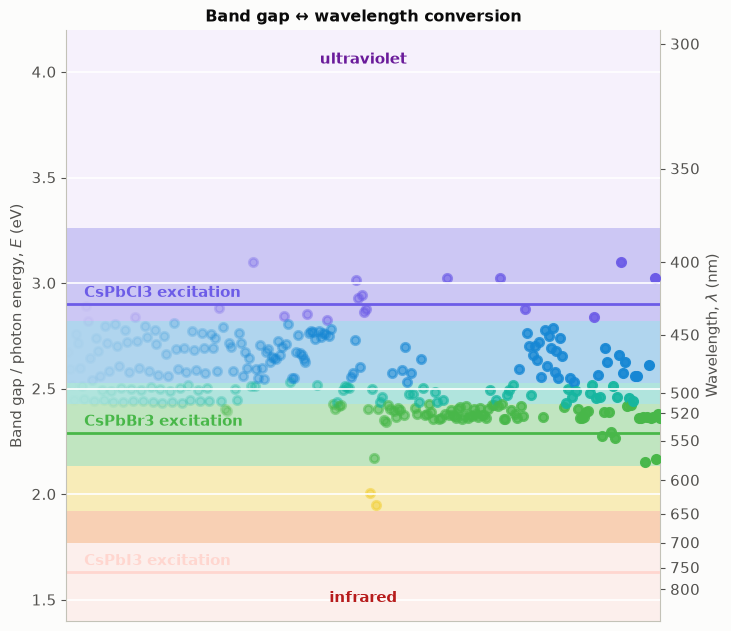

In [ ]:
"""Plot the nonlinear band-gap (eV) to wavelength (nm) conversion.

Run with:
    python plot_bandgap_wavelength.py
"""

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np


HC_EV_NM = 1239.841984  # Planck's constant times c, in eV nm


def wavelength_nm(bandgap_ev):
    """Convert photon energy / optical band gap in eV to wavelength in nm."""
    return HC_EV_NM / np.asarray(bandgap_ev)


def bandgap_ev(wavelength):
    """Convert wavelength in nm to photon energy in eV."""
    # Matplotlib may briefly ask the inverse transform about zero while it
    # lays out the secondary axis.  Infinity is the physically correct limit.
    with np.errstate(divide="ignore", invalid="ignore"):
        return HC_EV_NM / np.asarray(wavelength)


def wavelength_color(wavelength):
    """Approximate visible-light RGB color; UV/IR are deliberately pale."""
    if wavelength < 380:
        return "#eadcff"  # ultraviolet
    if wavelength < 440:
        return "#6c5ce7"
    if wavelength < 490:
        return "#1687d4"
    if wavelength < 510:
        return "#16b6a0"
    if wavelength < 580:
        return "#48b749"
    if wavelength < 645:
        return "#f2ce31"
    if wavelength <= 700:
        return "#f07824"
    return "#ffd6cf"  # infrared


def main():
    e_min, e_max = 1.4, 4.2
    fig, ax = plt.subplots(figsize=(7.2, 6.2), constrained_layout=True)

    # A color strip whose position is computed from wavelength, not drawn on a
    # linear wavelength scale. This is the key detail in a dual eV/nm plot.
    wavelengths = np.linspace(wavelength_nm(e_max), wavelength_nm(e_min), 500)
    for lower, upper in zip(wavelengths[:-1], wavelengths[1:]):
        midpoint = (lower + upper) / 2
        ax.axhspan(
            bandgap_ev(upper), bandgap_ev(lower),
            color=wavelength_color(midpoint), alpha=0.33, linewidth=0, zorder=0,
        )

    ax.set_xlim(0, 1)
    ax.set_xticks([])
    ax.set_ylim(e_min, e_max)
    ax.set_ylabel("Band gap / photon energy, $E$ (eV)")
    ax.set_title("Band gap ↔ wavelength conversion")
    ax.grid(axis="y", color="white", linewidth=1.2)

    right = ax.secondary_yaxis("right", functions=(wavelength_nm, bandgap_ev))
    right.set_ylabel("Wavelength, $\\lambda$ (nm)")
    right.set_yticks([300, 350, 400, 450, 500, 520, 550, 600, 650, 700, 750, 800])

    # Reference values relevant to a 473 nm-excited, ~520 nm-emitting sample.
    # BANDGAP_FOR_PHASE = {
    #         "CsPbBr3": 2.29, # Bandgap - 2.29-2.34, Red
    #         "CsPbI3": 1.63, # Bandgap - 1.63-1.75, 
    #         "CsPbCl3": 2.90, # Bandgap - 2.90-3.03
    #     }
    references = [
        (2.29, "CsPbBr3 excitation", wavelength_color(1240/2.29)),
        (1.63, "CsPbI3 excitation", wavelength_color(1240/1.63)),
        (2.90, "CsPbCl3 excitation", wavelength_color(1240/2.90)),
    ]

    ind_max = np.max(index)
    for ind, peak in zip(index, peaks):
        ax.scatter(ind/ind_max, bandgap_ev(peak), color=wavelength_color(peak), alpha=ind/ind_max, linewidth=2)


    for energy, label, color in references:
        ax.axhline(energy, color=color, linewidth=2)
        ax.text(0.03, energy + 0.035, label, color=color, weight="bold")

    ax.text(0.5, 4.04, "ultraviolet", ha="center", color="#6a1b9a", weight="bold")
    ax.text(0.5, 1.49, "infrared", ha="center", color="#b71c1c", weight="bold")

main()



Pareto-optimal trials (on target, observed):
  trial 154: Peak 515.7 nm, log_PLQY -0.91, log_FWHM 2.88  <- CsPb 62.1, Br 138.6, Cl 148.6, I 85.9
  trial 159: Peak 515.9 nm, log_PLQY -0.25, log_FWHM 2.89  <- CsPb 121.2, Br 73.4, Cl 181.6, I 98.8
  trial 170: Peak 516.8 nm, log_PLQY -1.95, log_FWHM 2.89  <- CsPb 223.3, Br 231.4, Cl 245.0, I 127.5
  trial 172: Peak 521.7 nm, log_PLQY 2.62, log_FWHM 2.91  <- CsPb 123.8, Br 93.3, Cl 141.4, I 84.7
  trial 179: Peak 520.8 nm, log_PLQY -1.12, log_FWHM 2.91  <- CsPb 250.0, Br 181.4, Cl 227.6, I 126.9
  trial 186: Peak 518.6 nm, log_PLQY -1.24, log_FWHM 2.90  <- CsPb 121.4, Br 87.8, Cl 239.7, I 144.1
  trial 193: Peak 520.5 nm, log_PLQY -1.59, log_FWHM 2.91  <- CsPb 134.6, Br 136.1, Cl 183.6, I 109.8
  trial 195: Peak 521.9 nm, log_PLQY -0.42, log_FWHM 2.91  <- CsPb 181.0, Br 166.7, Cl 245.6, I 151.7
  trial 200: Peak 515.5 nm, log_PLQY -0.80, log_FWHM 2.88  <- CsPb 10.0, Br 98.0, Cl 244.8, I 154.7
  trial 208: Peak 516.0 nm, log_PLQY -1.71, l

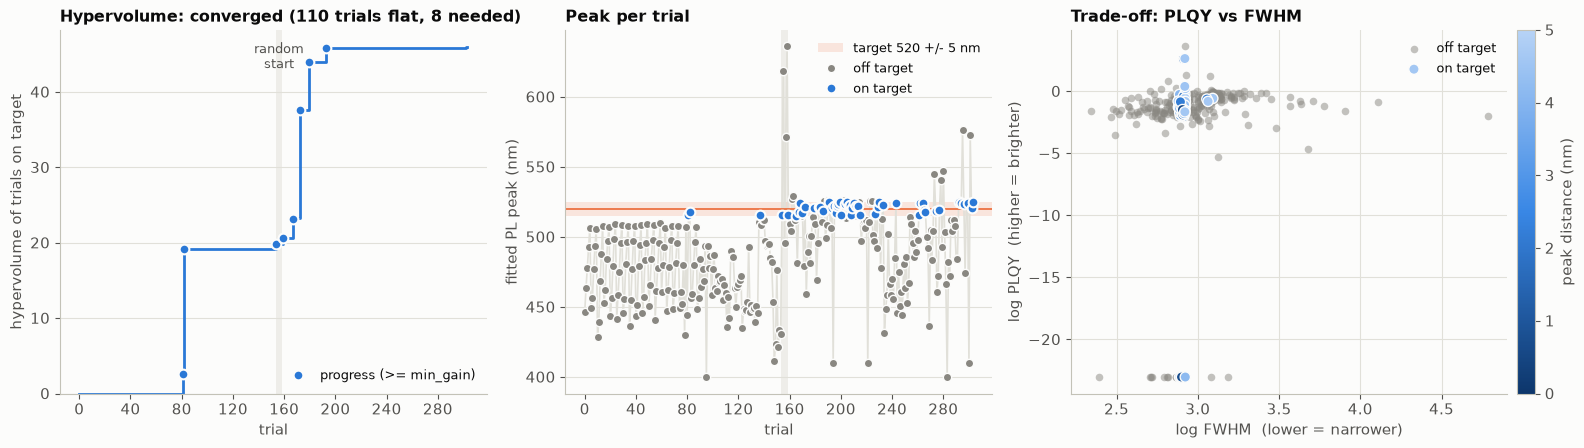

In [58]:
"""
Has a UV-Vis campaign converged? Tracks the hypervolume of the trials within peak_target +/- peak_tolerance.

The agent's three objectives (log_FWHM down, log_PLQY up, peak_distance down) trade off against each other, so
individual trials keep moving after the job is done. Convergence is the Pareto front no longer improving: the
hypervolume it dominates above a fixed reference point has not grown by min_gain in patience model trials.

Usage, in the notebook after the optimize cell:
  from convergence import check_convergence
  df = check_convergence(build_agent, run_agent)                         # table, verdict, Pareto trials, plots
  df = check_convergence(build_agent, run_agent, save="convergence.png") # also writes the figure
"""
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from botorch.utils.multi_objective.hypervolume import Hypervolume
from botorch.utils.multi_objective.pareto import is_non_dominated
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MaxNLocator

INK, INK_2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
BLUE, ORANGE = "#2a78d6", "#eb6834"
BLUES = LinearSegmentedColormap.from_list("blues", ["#0d366b", "#3987e5", "#b7d3f6"])  # dark = on target


def check_convergence(
    build_agent,
    run_agent,
    ref: dict[str, float] | None = None,
    min_gain: float = 0.01,
    patience: int = 8,
    plot: bool = True,
    save: str | None = None,
) -> pd.DataFrame:
    """
    Print the hypervolume trace, whether it has converged and the Pareto-optimal trials; plot them; return the trace.

    Args:
        - build_agent, run_agent: the notebook's BuildAgent and the agent build_local() returned
        - ref: reference point, the worst values you'd still accept; default FWHM 60 nm, PLQY 1e-3 and
          peak_distance = peak_tolerance. Only trials better on every objective add hypervolume; keep it
          fixed for a campaign, since changing it rescales the hypervolume
        - min_gain: a trial counts as progress if it grows the hypervolume by at least this fraction
        - patience: this many model (non-Sobol) trials in a row without progress = converged
        - plot: draw the hypervolume trace, Peak per trial and the PLQY/FWHM trade-off
        - save: also write the figure to this path

    Returns:
        - the completed trials with feasible, hypervolume, improved and pareto columns
    """
    target, tol = build_agent.peak_target, build_agent.peak_tolerance
    ref = ref or {"log_FWHM": np.log(60.0), "log_PLQY": np.log(1e-3), "peak_distance": tol}

    df = run_agent.ax_client.summarize().sort_values("trial_index").reset_index(drop=True)
    df = df[df["trial_status"] == "COMPLETED"].reset_index(drop=True)
    df["feasible"] = (df["Peak"] - target).abs() <= tol
    feasible = df["feasible"].to_numpy()

    # Hypervolume maximizes, so flip the minimized objectives.
    y = torch.tensor(np.column_stack([-df["log_FWHM"], df["log_PLQY"], -df["peak_distance"]]), dtype=torch.double)
    ref_point = torch.tensor([-ref["log_FWHM"], ref["log_PLQY"], -ref["peak_distance"]], dtype=torch.double)
    hv = Hypervolume(ref_point=ref_point)
    trace = []
    for i in range(len(df)):
        pts = y[: i + 1][torch.from_numpy(feasible[: i + 1])]
        pts = pts[(pts > ref_point).all(dim=1)]
        trace.append(hv.compute(pts[is_non_dominated(pts)]) if len(pts) else 0.0)
    df["hypervolume"] = trace
    best_before = df["hypervolume"].cummax().shift(fill_value=0.0)
    df["improved"] = df["hypervolume"] > best_before * (1 + min_gain) + 1e-12

    stale = 0
    for gained in df.loc[df["generation_node"] != "Sobol", "improved"][::-1]:
        if gained:
            break
        stale += 1
    converged = stale >= patience

    # Pareto set on the same footing as the hypervolume: on-target trials, all three objectives.
    # (Ax's get_pareto_frontier also drops points below thresholds it infers, so it can disagree.)
    df["pareto"] = False
    if feasible.any():
        df.loc[feasible, "pareto"] = is_non_dominated(y[torch.from_numpy(feasible)]).numpy()

    cols = ["trial_index", "generation_node", "Peak", "log_PLQY", "log_FWHM", "hypervolume", "improved"]
    # print(df[cols].round(3).to_string())
    # print(f"\n{feasible.sum()} of {len(df)} trials within {target:g} +/- {tol:g} nm; hypervolume {trace[-1]:.4g}; "
    #       f"{stale} model trials since the last gain -> {'converged' if converged else 'still improving'}")
    print("\n",88*"=")
    print("\nPareto-optimal trials (on target, observed):")
    dofs = [col for col in df.columns if col.startswith("infusion_rate_")]
    for _, row in df[df["pareto"]].iterrows():
        rates = ", ".join(f"{dof.removeprefix('infusion_rate_')} {row[dof]:.1f}" for dof in dofs)
        print(f"  trial {int(row['trial_index'])}: Peak {row['Peak']:.1f} nm, log_PLQY {row['log_PLQY']:.2f}, "
              f"log_FWHM {row['log_FWHM']:.2f}  <- {rates}")
    print("\n",88*"=")

    if plot:
        fig = plot_convergence(df, target, tol, stale, converged, patience)
        if save:
            fig.savefig(save, dpi=170)
        plt.show()
    return df


def plot_convergence(df: pd.DataFrame, target: float, tol: float, stale: int, converged: bool,
                     patience: int) -> plt.Figure:
    """Hypervolume per trial, Peak per trial against the target band, and the PLQY/FWHM trade-off."""
    plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
                         "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK_2, "xtick.color": INK_2,
                         "ytick.color": INK_2, "text.color": INK, "font.size": 10.5, "axes.titlesize": 11.5,
                         "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})
    fig, (a, b, c) = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1, 1, 1.1]})
    trials = df["trial_index"].to_numpy()
    sobol = (df["generation_node"] == "Sobol").to_numpy()
    for ax in (a, b):
        if sobol.any():
            ax.axvspan(trials[sobol].min() - 0.5, trials[sobol].max() + 0.5, color=GRID, alpha=0.5, lw=0)
        ax.set_xlabel("trial")
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.grid(axis="y", color=GRID, lw=0.8)
        ax.set_axisbelow(True)

    # 1: hypervolume trace
    a.step(trials, df["hypervolume"], where="post", color=BLUE, lw=2)
    gains = df["improved"].to_numpy()
    a.plot(trials[gains], df["hypervolume"][gains], "o", color=BLUE, ms=7, mec=SURFACE, mew=1.5,
           label="progress (>= min_gain)")
    if sobol.any():
        a.text(trials[sobol].mean(), 0.97, "random\nstart", ha="center", va="top", color=INK_2, fontsize=9,
               transform=a.get_xaxis_transform())
    a.set_ylim(bottom=0)
    a.set_ylabel("hypervolume of trials on target")
    verdict = "converged" if converged else "still improving"
    a.set_title(f"Hypervolume: {verdict} ({stale} trials flat, {patience} needed)", loc="left")
    a.legend(frameon=False, loc="lower right", fontsize=9)

    # 2: Peak per trial vs the target band
    peak = df["Peak"].to_numpy()
    ok = df["feasible"].to_numpy()
    b.axhspan(target - tol, target + tol, color=ORANGE, alpha=0.15, lw=0, label=f"target {target:g} +/- {tol:g} nm")
    b.axhline(target, color=ORANGE, lw=1.2)
    b.plot(trials, peak, color=GRID, lw=1.2, zorder=1)
    b.plot(trials[~ok], peak[~ok], "o", color=MUTED, ms=6, mec=SURFACE, mew=1, label="off target", zorder=2)
    b.plot(trials[ok], peak[ok], "o", color=BLUE, ms=7, mec=SURFACE, mew=1.5, label="on target", zorder=3)
    b.set_ylabel("fitted PL peak (nm)")
    b.set_title("Peak per trial", loc="left")
    b.legend(frameon=False, loc="best", fontsize=9)

    # 3: PLQY vs FWHM trade-off; on-target trials coloured by distance, Pareto-optimal circled
    off = df[~df["feasible"]]
    on = df[df["feasible"]]
    c.scatter(off["log_FWHM"], off["log_PLQY"], s=30, color=MUTED, alpha=0.5, lw=0, label="off target")
    sc = c.scatter(on["log_FWHM"], on["log_PLQY"], s=55, c=on["peak_distance"], cmap=BLUES, vmin=0, vmax=tol,
                   edgecolors=SURFACE, linewidths=1, zorder=3, label="on target")
    front = on[on["pareto"]]
    # c.scatter(front["log_FWHM"], front["log_PLQY"], s=150, facecolors="none", edgecolors=ORANGE, linewidths=2,
    #           zorder=4, label="Pareto-optimal")
    # for _, row in front.iterrows():
    #     c.annotate(f"{int(row['trial_index'])}", (row["log_FWHM"], row["log_PLQY"]), xytext=(7, 5),
    #                textcoords="offset points", fontsize=9, color=INK_2)
    fig.colorbar(sc, ax=c, label="peak distance (nm)", fraction=0.05, pad=0.02)
    c.ticklabel_format(useOffset=False)
    span = df["log_FWHM"].max() - df["log_FWHM"].min()
    if span < 1e-3:                                     # constant FWHM (e.g. simulated): show a sane window
        mid = df["log_FWHM"].mean()
        c.set_xlim(mid - 0.05, mid + 0.05)
    c.set_xlabel("log FWHM  (lower = narrower)")
    c.set_ylabel("log PLQY  (higher = brighter)")
    c.set_title("Trade-off: PLQY vs FWHM", loc="left")
    c.grid(color=GRID, lw=0.8)
    c.set_axisbelow(True)
    c.legend(frameon=False, fontsize=9)

    fig.tight_layout()
    return fig


outdf = check_convergence(build_agent, run_agent, save = "convergence.png")